In [ ]:
# TF-IDF Information Retrieval Assignment
# Dataset: Artificial Intelligence and Technology

documents = {
    "D1": "Artificial intelligence helps machines learn from data.",
    "D2": "Machine learning improves prediction using data.",
    "D3": "Deep learning uses neural networks for intelligence.",
    "D4": "Artificial intelligence automates tasks and improves efficiency.",
    "D5": "Data science analyzes data to find useful patterns.",
    "D6": "Neural networks help computers recognize images.",
    "D7": "Machine learning supports intelligent decision making.",
    "D8": "Artificial intelligence is used in healthcare technology.",
    "D9": "Robots use artificial intelligence to perform tasks.",
    "D10": "Deep learning improves image recognition systems."
}

# Display the document collection
for doc_id, text in documents.items():
    print(f"{doc_id}: {text}")

D1: Artificial intelligence helps machines learn from data.
D2: Machine learning improves prediction using data.
D3: Deep learning uses neural networks for intelligence.
D4: Artificial intelligence automates tasks and improves efficiency.
D5: Data science analyzes data to find useful patterns.
D6: Neural networks help computers recognize images.
D7: Machine learning supports intelligent decision making.
D8: Artificial intelligence is used in healthcare technology.
D9: Robots use artificial intelligence to perform tasks.
D10: Deep learning improves image recognition systems.


In [ ]:
import pandas as pd

document_details = [
    ["D1", "Introduction to AI", "Artificial Intelligence", "Self-created"],
    ["D2", "Machine Learning", "Artificial Intelligence", "Self-created"],
    ["D3", "Deep Learning", "Artificial Intelligence", "Self-created"],
    ["D4", "AI Automation", "Artificial Intelligence", "Self-created"],
    ["D5", "Data Science", "Data Science", "Self-created"],
    ["D6", "Neural Networks", "Deep Learning", "Self-created"],
    ["D7", "Intelligent Decision Making", "Machine Learning", "Self-created"],
    ["D8", "AI in Healthcare", "Healthcare AI", "Self-created"],
    ["D9", "Robotics and AI", "Robotics", "Self-created"],
    ["D10", "Image Recognition", "Deep Learning", "Self-created"]
]

df_documents = pd.DataFrame(
    document_details,
    columns=["Document ID", "Title", "Topic", "Source/Author"]
)

df_documents

,Document ID,Title,Topic,Source/Author
0,D1,Introduction to AI,Artificial Intelligence,Self-created
1,D2,Machine Learning,Artificial Intelligence,Self-created
2,D3,Deep Learning,Artificial Intelligence,Self-created
3,D4,AI Automation,Artificial Intelligence,Self-created
4,D5,Data Science,Data Science,Self-created
5,D6,Neural Networks,Deep Learning,Self-created
6,D7,Intelligent Decision Making,Machine Learning,Self-created
7,D8,AI in Healthcare,Healthcare AI,Self-created
8,D9,Robotics and AI,Robotics,Self-created
9,D10,Image Recognition,Deep Learning,Self-created


text preprocessing


In [ ]:
import nltk
import re

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')

# Initialize stop words and stemmer
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

# Preprocessing function
def preprocess_text(text):
    # Step 1: Lowercase
    text = text.lower()

    # Step 2: Tokenization
    tokens = re.findall(r'\b[a-z]+\b', text)

    # Step 3: Stop-word removal
    tokens = [word for word in tokens if word not in stop_words]

    # Step 4: Stemming
    tokens = [stemmer.stem(word) for word in tokens]

    return tokens

# Apply preprocessing to all documents
processed_documents = {
    doc_id: preprocess_text(text)
    for doc_id, text in documents.items()
}

# Show before and after preprocessing
print("BEFORE PREPROCESSING:")
print(documents["D1"])

print("\nAFTER PREPROCESSING:")
print(processed_documents["D1"])

print("\nALL PREPROCESSED DOCUMENTS:")
for doc_id, tokens in processed_documents.items():
    print(doc_id, ":", tokens)

BEFORE PREPROCESSING:
Artificial intelligence helps machines learn from data.

AFTER PREPROCESSING:
['artifici', 'intellig', 'help', 'machin', 'learn', 'data']

ALL PREPROCESSED DOCUMENTS:
D1 : ['artifici', 'intellig', 'help', 'machin', 'learn', 'data']
D2 : ['machin', 'learn', 'improv', 'predict', 'use', 'data']
D3 : ['deep', 'learn', 'use', 'neural', 'network', 'intellig']
D4 : ['artifici', 'intellig', 'autom', 'task', 'improv', 'effici']
D5 : ['data', 'scienc', 'analyz', 'data', 'find', 'use', 'pattern']
D6 : ['neural', 'network', 'help', 'comput', 'recogn', 'imag']
D7 : ['machin', 'learn', 'support', 'intellig', 'decis', 'make']
D8 : ['artifici', 'intellig', 'use', 'healthcar', 'technolog']
D9 : ['robot', 'use', 'artifici', 'intellig', 'perform', 'task']
D10 : ['deep', 'learn', 'improv', 'imag', 'recognit', 'system']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


term document matrix


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Convert preprocessed tokens back into text
processed_texts = [
    " ".join(processed_documents[doc_id])
    for doc_id in documents.keys()
]

# Create Term-Document Matrix
vectorizer = CountVectorizer()
tdm = vectorizer.fit_transform(processed_texts)

# Convert matrix into DataFrame
tdm_df = pd.DataFrame(
    tdm.toarray(),
    index=documents.keys(),
    columns=vectorizer.get_feature_names_out()
)

print("TERM-DOCUMENT MATRIX:")
display(tdm_df)

TERM-DOCUMENT MATRIX:


,analyz,artifici,autom,comput,data,decis,deep,effici,find,healthcar,...,predict,recogn,recognit,robot,scienc,support,system,task,technolog,use
D1,0,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
D2,0,0,0,0,1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
D3,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
D4,0,1,1,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
D5,1,0,0,0,2,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
D6,0,0,0,1,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
D7,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
D8,0,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,1
D9,0,1,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,1
D10,0,0,0,0,0,0,1,0,0,0,...,0,0,1,0,0,0,1,0,0,0


calculation

In [ ]:
import numpy as np
import pandas as pd

# Total number of documents
N = len(documents)

# Term Frequency (TF)
TF = tdm_df.copy()

# Document Frequency (DF)
DF = (tdm_df > 0).sum(axis=0)

# Inverse Document Frequency (IDF)
IDF = np.log10(N / DF)

# Display TF
print("TERM FREQUENCY (TF)")
display(TF)

# Display DF
print("DOCUMENT FREQUENCY (DF)")
display(DF.to_frame(name="DF"))

# Display IDF
print("INVERSE DOCUMENT FREQUENCY (IDF)")
display(IDF.to_frame(name="IDF"))

TERM FREQUENCY (TF)


,analyz,artifici,autom,comput,data,decis,deep,effici,find,healthcar,...,predict,recogn,recognit,robot,scienc,support,system,task,technolog,use
D1,0,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
D2,0,0,0,0,1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
D3,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
D4,0,1,1,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
D5,1,0,0,0,2,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
D6,0,0,0,1,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
D7,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
D8,0,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,1
D9,0,1,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,1
D10,0,0,0,0,0,0,1,0,0,0,...,0,0,1,0,0,0,1,0,0,0


DOCUMENT FREQUENCY (DF)


,DF
analyz,1
artifici,4
autom,1
comput,1
data,3
decis,1
deep,2
effici,1
find,1
healthcar,1


INVERSE DOCUMENT FREQUENCY (IDF)


,IDF
analyz,1.000000
artifici,0.397940
autom,1.000000
comput,1.000000
data,0.522879
decis,1.000000
deep,0.698970
effici,1.000000
find,1.000000
healthcar,1.000000


In [ ]:
tf-idf

In [ ]:
# Calculate TF-IDF matrix
TF_IDF = TF.mul(IDF, axis=1)

print("TF-IDF MATRIX:")
display(TF_IDF.round(4))

TF-IDF MATRIX:


,analyz,artifici,autom,comput,data,decis,deep,effici,find,healthcar,...,predict,recogn,recognit,robot,scienc,support,system,task,technolog,use
D1,0.0,0.3979,0.0,0.0,0.5229,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.000
D2,0.0,0.0000,0.0,0.0,0.5229,0.0,0.000,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.301
D3,0.0,0.0000,0.0,0.0,0.0000,0.0,0.699,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.301
D4,0.0,0.3979,1.0,0.0,0.0000,0.0,0.000,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.699,0.0,0.000
D5,1.0,0.0000,0.0,0.0,1.0458,0.0,0.000,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.000,0.0,0.301
D6,0.0,0.0000,0.0,1.0,0.0000,0.0,0.000,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.000
D7,0.0,0.0000,0.0,0.0,0.0000,1.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.000,0.0,0.000
D8,0.0,0.3979,0.0,0.0,0.0000,0.0,0.000,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,1.0,0.301
D9,0.0,0.3979,0.0,0.0,0.0000,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.699,0.0,0.301
D10,0.0,0.0000,0.0,0.0,0.0000,0.0,0.699,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.000,0.0,0.000


visulize tf-idf

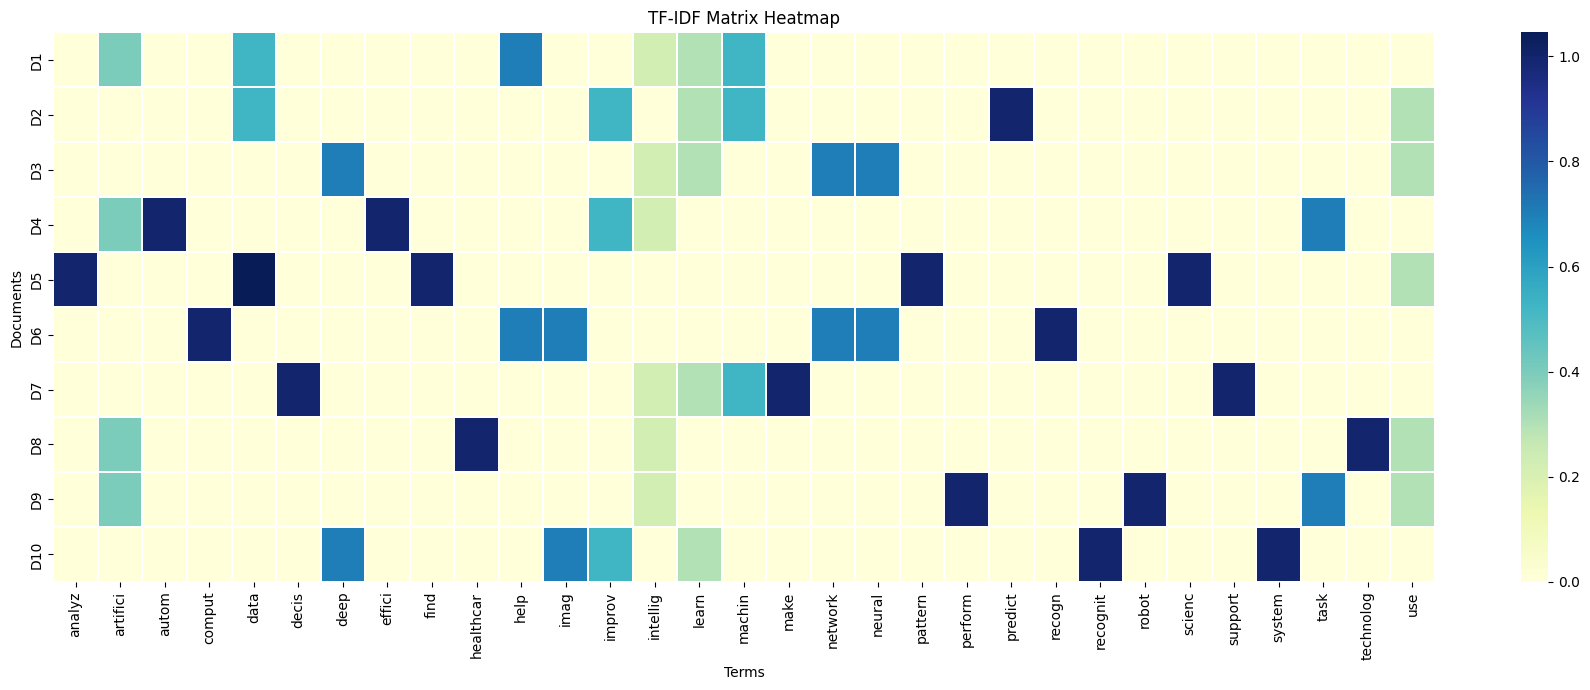

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 7))

sns.heatmap(
    TF_IDF,
    cmap="YlGnBu",
    annot=False,
    linewidths=0.3
)

plt.title("TF-IDF Matrix Heatmap")
plt.xlabel("Terms")
plt.ylabel("Documents")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
import math

# Manual calculation for the term 'artifici' in document D1
term = "artifici"
doc_id = "D1"

# TF: frequency of the term in D1
tf_value = TF.loc[doc_id, term]

# DF: number of documents containing the term
df_value = DF[term]

# Total documents
N = len(documents)

# IDF calculation
idf_value = math.log10(N / df_value)

# TF-IDF calculation
tfidf_value = tf_value * idf_value

print("MANUAL TF-IDF CALCULATION")
print("-------------------------")
print(f"Term             : {term}")
print(f"Document         : {doc_id}")
print(f"TF              : {tf_value}")
print(f"DF              : {df_value}")
print(f"Total documents  : {N}")
print(f"IDF             : log10({N}/{df_value}) = {idf_value:.4f}")
print(f"TF-IDF          : {tf_value} × {idf_value:.4f}")
print(f"Final TF-IDF    : {tfidf_value:.4f}")

MANUAL TF-IDF CALCULATION
-------------------------
Term             : artifici
Document         : D1
TF              : 1
DF              : 4
Total documents  : 10
IDF             : log10(10/4) = 0.3979
TF-IDF          : 1 × 0.3979
Final TF-IDF    : 0.3979


In [ ]:
# Define three search queries
queries = {
    "Q1": "artificial intelligence",
    "Q2": "neural networks",
    "Q3": "healthcare technology"
}

# Preprocess all queries using the same function
processed_queries = {
    query_id: preprocess_text(query)
    for query_id, query in queries.items()
}

# Display original and processed queries
print("QUERY PROCESSING")
print("=" * 50)

for query_id, query in queries.items():
    print(f"\n{query_id}: {query}")
    print("Processed:", processed_queries[query_id])

QUERY PROCESSING

Q1: artificial intelligence
Processed: ['artifici', 'intellig']

Q2: neural networks
Processed: ['neural', 'network']

Q3: healthcare technology
Processed: ['healthcar', 'technolog']


In [ ]:
# Convert processed queries into text
processed_query_texts = [
    " ".join(processed_queries[qid])
    for qid in queries
]

# Convert queries using the existing vectorizer
query_tdm = vectorizer.transform(processed_query_texts)

# Apply IDF weights
query_tfidf = query_tdm.toarray() * IDF.values

# Create DataFrame
query_tfidf_df = pd.DataFrame(
    query_tfidf,
    index=queries.keys(),
    columns=vectorizer.get_feature_names_out()
)

print("QUERY TF-IDF MATRIX")
display(query_tfidf_df.round(4))

QUERY TF-IDF MATRIX


,analyz,artifici,autom,comput,data,decis,deep,effici,find,healthcar,...,predict,recogn,recognit,robot,scienc,support,system,task,technolog,use
Q1,0.0,0.3979,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Q2,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Q3,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate cosine similarity between queries and documents
similarity_matrix = cosine_similarity(query_tfidf, TF_IDF)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=queries.keys(),
    columns=documents.keys()
)

print("COSINE SIMILARITY MATRIX")
display(similarity_df.round(4))

COSINE SIMILARITY MATRIX


,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
Q1,0.3945,0.0,0.0829,0.2644,0.0,0.0000,0.0585,0.3005,0.2729,0.0
Q2,0.0000,0.0,0.7590,0.0000,0.0,0.4971,0.0000,0.0000,0.0000,0.0
Q3,0.0000,0.0,0.0000,0.0000,0.0,0.0000,0.0000,0.9329,0.0000,0.0


In [ ]:
# Rank documents for each query
print("DOCUMENT RETRIEVAL AND RANKING")
print("=" * 60)

ranked_results = {}

for query_id in queries:
    scores = similarity_df.loc[query_id].sort_values(ascending=False)
    ranked_results[query_id] = scores

    print(f"\n{query_id}: {queries[query_id]}")
    print("-" * 40)

    for rank, (doc_id, score) in enumerate(scores.items(), start=1):
        print(f"Rank {rank}: {doc_id} | Similarity Score: {score:.4f}".replace(
            "doc_id", doc_id
        ))

DOCUMENT RETRIEVAL AND RANKING

Q1: artificial intelligence
----------------------------------------
Rank 1: D1 | Similarity Score: 0.3945
Rank 2: D8 | Similarity Score: 0.3005
Rank 3: D9 | Similarity Score: 0.2729
Rank 4: D4 | Similarity Score: 0.2644
Rank 5: D3 | Similarity Score: 0.0829
Rank 6: D7 | Similarity Score: 0.0585
Rank 7: D2 | Similarity Score: 0.0000
Rank 8: D5 | Similarity Score: 0.0000
Rank 9: D6 | Similarity Score: 0.0000
Rank 10: D10 | Similarity Score: 0.0000

Q2: neural networks
----------------------------------------
Rank 1: D3 | Similarity Score: 0.7590
Rank 2: D6 | Similarity Score: 0.4971
Rank 3: D2 | Similarity Score: 0.0000
Rank 4: D1 | Similarity Score: 0.0000
Rank 5: D4 | Similarity Score: 0.0000
Rank 6: D5 | Similarity Score: 0.0000
Rank 7: D7 | Similarity Score: 0.0000
Rank 8: D8 | Similarity Score: 0.0000
Rank 9: D9 | Similarity Score: 0.0000
Rank 10: D10 | Similarity Score: 0.0000

Q3: healthcare technology
----------------------------------------
Rank 

In [ ]:
# Test query containing unknown terms
unknown_query = "quantum banana"

# Preprocess unknown query
processed_unknown = preprocess_text(unknown_query)

# Convert to vector using existing vocabulary
unknown_vector = vectorizer.transform([" ".join(processed_unknown)])

# Calculate similarity
unknown_scores = cosine_similarity(unknown_vector, TF_IDF)[0]

unknown_results = pd.Series(
    unknown_scores,
    index=documents.keys()
).sort_values(ascending=False)

print("UNKNOWN TERM QUERY TEST")
print("Original Query:", unknown_query)
print("Processed Query:", processed_unknown)
print("\nRanking Results:")
display(unknown_results.to_frame("Similarity Score").round(4))

UNKNOWN TERM QUERY TEST
Original Query: quantum banana
Processed Query: ['quantum', 'banana']

Ranking Results:


,Similarity Score
D1,0.0
D2,0.0
D3,0.0
D4,0.0
D5,0.0
D6,0.0
D7,0.0
D8,0.0
D9,0.0
D10,0.0


In [ ]:
print("OBSERVATIONS AND ANALYSIS")
print("=" * 60)

print("""
1. Term Frequency (TF):
   A term occurring more frequently in a document receives a higher
   term frequency value.

2. Document Frequency (DF):
   Terms appearing in many documents have higher document frequency
   and are less useful for distinguishing individual documents.

3. Inverse Document Frequency (IDF):
   Rare terms receive higher IDF values, while terms occurring in
   every document receive an IDF of zero under our formula.

4. TF-IDF:
   TF-IDF combines term frequency and rarity to identify terms
   that are important in a particular document.

5. Document Ranking:
   Documents with higher cosine similarity scores are ranked as
   more relevant to the user's query.

6. Unknown Terms:
   Queries containing only terms outside the dataset vocabulary
   produce zero similarity scores because no matching terms exist.
""")

OBSERVATIONS AND ANALYSIS

1. Term Frequency (TF):
   A term occurring more frequently in a document receives a higher
   term frequency value.

2. Document Frequency (DF):
   Terms appearing in many documents have higher document frequency
   and are less useful for distinguishing individual documents.

3. Inverse Document Frequency (IDF):
   Rare terms receive higher IDF values, while terms occurring in
   every document receive an IDF of zero under our formula.

4. TF-IDF:
   TF-IDF combines term frequency and rarity to identify terms
   that are important in a particular document.

5. Document Ranking:
   Documents with higher cosine similarity scores are ranked as
   more relevant to the user's query.

6. Unknown Terms:
   Queries containing only terms outside the dataset vocabulary
   produce zero similarity scores because no matching terms exist.



In [ ]:
# Display top 3 documents for each query

print("FINAL TOP-3 RETRIEVAL RESULTS")
print("=" * 60)

for query_id, query in queries.items():

    scores = similarity_df.loc[query_id].sort_values(
        ascending=False
    ).head(3)

    print(f"\nQuery: {query}")
    print(f"Query ID: {query_id}")
    print("-" * 40)

    for rank, (doc_id, score) in enumerate(scores.items(), start=1):
        print(f"{rank}. {doc_id} | Score: {score:.4f}")
        print(f"   Document: {documents[doc_id]}")

FINAL TOP-3 RETRIEVAL RESULTS

Query: artificial intelligence
Query ID: Q1
----------------------------------------
1. D1 | Score: 0.3945
   Document: Artificial intelligence helps machines learn from data.
2. D8 | Score: 0.3005
   Document: Artificial intelligence is used in healthcare technology.
3. D9 | Score: 0.2729
   Document: Robots use artificial intelligence to perform tasks.

Query: neural networks
Query ID: Q2
----------------------------------------
1. D3 | Score: 0.7590
   Document: Deep learning uses neural networks for intelligence.
2. D6 | Score: 0.4971
   Document: Neural networks help computers recognize images.
3. D2 | Score: 0.0000
   Document: Machine learning improves prediction using data.

Query: healthcare technology
Query ID: Q3
----------------------------------------
1. D8 | Score: 0.9329
   Document: Artificial intelligence is used in healthcare technology.
2. D1 | Score: 0.0000
   Document: Artificial intelligence helps machines learn from data.
3. D2 | Sc